# Detector and Verifier Threshold Tuning

This notebook compares detector confidence and verifier probability thresholds for the model pair from fine-tuning run 3. It uses the data, labels, and helper functions from that run without retraining either model.


## 01. Load the checkpoint paths and search grid

Checks the saved weights and validation inputs and defines the baseline confidence cutoffs and recall constraint.


In [25]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import yaml
from IPython.display import display
from tqdm.auto import tqdm

TUNE_DIR = (
    Path("/kaggle/working/final_fire_smoke/20261115_102627_437619")
    / "last_epoch_verifier"
)
TUNE_YOLO = TUNE_DIR / "detector_last_epoch.pt"
TUNE_VER = TUNE_DIR / "verifier_final.pt"

for p in (TUNE_YOLO, TUNE_VER):
    if not p.is_file():
        raise FileNotFoundError(f"Missing saved weights: {p}")

required = (
    "SPLITS", "LABELS", "DEVICE", "detector_for", "square_crop",
    "pixel_targets", "pred_boxes", "box_iou", "release_gpu",
)
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Notebook state missing: {missing}. Don't rerun training.")

for split, count in (("val", 3764), ("hard_val", 869)):
    paths = SPLITS.get(split, [])
    if len(paths) != count or any(p not in LABELS or not p.is_file() for p in paths):
        raise RuntimeError(
            f"Expected {count} ready images and labels for {split}. Found {len(paths)} paths."
        )

TUNE_OUT = TUNE_DIR / "threshold_tuning"
TUNE_OUT.mkdir(exist_ok=True)

BASE_CUTOFF = (0.20, 0.70)
DET_GRID = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
VER_GRID = [0.35, 0.45, 0.55, 0.65, 0.70, 0.75, 0.85, 0.90, 0.95]
RECALL_DROP_MAX = 0.01  # Allow at most 1 percentage point of recall loss per class on val.

print("Ready | epoch 11 YOLO + final verifier | val=3764 | hard_val=869")

Ready | epoch 11 YOLO + final verifier | val=3764 | hard_val=869


## 02. Cache validation predictions

Runs the detector and verifier once and stores per-box scores and overlaps for the threshold sweep.


In [26]:
def tune_collect(split):
    device = f"cuda:{DEVICE}"
    detector = detector_for(TUNE_YOLO)
    ck = torch.load(TUNE_VER, map_location="cpu", weights_only=True)
    classes = list(ck["classes"])

    net = torchvision.models.efficientnet_b0(weights=None)
    net.classifier[1] = torch.nn.Linear(net.classifier[1].in_features, len(classes))
    net.load_state_dict(ck["state_dict"], strict=True)
    net.to(device).eval()

    event_ids = [classes.index(c) for c in ("fire", "smoke")]
    size, pad = int(ck.get("imgsz", 224)), float(ck.get("pad", 0.30))
    mean = np.array([.485, .456, .406], dtype=np.float32)
    std = np.array([.229, .224, .225], dtype=np.float32)
    cache = []

    try:
        with torch.inference_mode():
            for path in tqdm(SPLITS[split], desc=f"Scoring {split}"):
                frame = cv2.imread(str(path))
                if frame is None:
                    raise ValueError(f"Cannot read {path}")

                h, w = frame.shape[:2]
                labels, gt = pixel_targets(path, w, h)
                result = detector.predict(
                    frame, imgsz=800, conf=min(DET_GRID), iou=.50,
                    max_det=50, device=device, quantize=16, rect=True, verbose=False,
                )[0]

                pred, crops = [], []
                for cls, score, box in pred_boxes(result):
                    crop = square_crop(frame, box, pad=pad)
                    if crop is None:
                        continue
                    interp = cv2.INTER_AREA if crop.shape[0] > size else cv2.INTER_LINEAR
                    crop = cv2.resize(crop, (size, size), interpolation=interp)
                    rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
                    crops.append((rgb - mean) / std)
                    pred.append((cls, score, box))

                prob = np.empty(0, dtype=np.float32)
                if crops:
                    x = np.ascontiguousarray(np.stack(crops).transpose(0, 3, 1, 2))
                    probs = net(torch.from_numpy(x).to(device)).float().softmax(1)
                    prob = probs[:, event_ids].sum(1).cpu().numpy()

                cache.append((
                    labels,
                    [p[0] for p in pred],
                    np.array([p[1] for p in pred]),
                    prob,
                    box_iou(gt, [p[2] for p in pred]),
                ))
    finally:
        del detector, net
        release_gpu()

    return cache

tune_val = tune_collect("val")
print(f"Cached {len(tune_val):,} validation images")

Scoring val:   0%|          | 0/3764 [00:00<?, ?it/s]

Cached 3,764 validation images


## 03. Score candidate thresholds

Tests 54 settings on validation and ranks their macro F1 subject to the limit on per-class recall loss.


In [27]:
def tune_score(cache, cutoff):
    d_min, v_min = cutoff
    cm = np.zeros((3, 3), dtype=np.int64)  # Rows actual, columns predicted.
    bg_flagged = 0

    for truth, pred, det, ver, iou in cache:
        keep = (det > d_min) & (ver >= v_min)
        bg_flagged += int(not truth and keep.any())

        # One-to-one matches by highest IoU. Wrong classes go off-diagonal.
        ii, jj = np.where((iou >= .50) & keep[None, :])
        used_gt, used_det = set(), set()
        for k in np.argsort(-iou[ii, jj], kind="stable"):
            i, j = ii[k], jj[k]
            if i not in used_gt and j not in used_det:
                cm[truth[i], pred[j]] += 1
                used_gt.add(i)
                used_det.add(j)

        for i, cls in enumerate(truth):
            if i not in used_gt:
                cm[cls, 2] += 1  # Missed labeled box.
        for j in np.flatnonzero(keep):
            if j not in used_det:
                cm[2, pred[j]] += 1  # Unmatched prediction.

    def prf(tp, predicted, actual):
        p = tp / max(int(predicted), 1)
        r = tp / max(int(actual), 1)
        return p, r, 2 * p * r / (p + r) if p + r else 0.0

    scores = {}
    for i, name in enumerate(("fire", "smoke")):
        p, r, f = prf(cm[i, i], cm[:, i].sum(), cm[i, :].sum())
        scores.update({f"{name}_P": p, f"{name}_R": r, f"{name}_F1": f})

    p, r, f = prf(cm[0, 0] + cm[1, 1], cm[:, :2].sum(), cm[:2, :].sum())
    scores.update(
        precision=p, recall=r, F1=f,
        macro_F1=(scores["fire_F1"] + scores["smoke_F1"]) / 2,
        bg_images_flagged=bg_flagged,
    )
    return scores, cm

baseline_val, _ = tune_score(tune_val, BASE_CUTOFF)
rows = []

for d in DET_GRID:
    for v in VER_GRID:
        scores, _ = tune_score(tune_val, (d, v))
        rows.append({"det_conf": d, "ver_conf": v, **scores})

grid = pd.DataFrame(rows).sort_values(["macro_F1", "F1"], ascending=False)
eligible = grid[
    (grid.fire_R >= baseline_val["fire_R"] - RECALL_DROP_MAX)
    & (grid.smoke_R >= baseline_val["smoke_R"] - RECALL_DROP_MAX)
]
pick = eligible.iloc[0]
TUNED_CUTOFF = (float(pick.det_conf), float(pick.ver_conf))

grid.to_csv(TUNE_OUT / "val_threshold_sweep.csv", index=False)
print("Baseline", BASE_CUTOFF, "| Selected on val", TUNED_CUTOFF)
display(eligible.head(8).round(4))

Baseline (0.2, 0.7) | Selected on val (0.15, 0.35)


,det_conf,ver_conf,fire_P,fire_R,fire_F1,smoke_P,smoke_R,smoke_F1,precision,recall,F1,macro_F1,bg_images_flagged
9,0.15,0.35,0.6246,0.6277,0.6262,0.8069,0.6577,0.7247,0.6892,0.6398,0.6636,0.6754,122
10,0.15,0.45,0.6280,0.6251,0.6265,0.8089,0.6499,0.7207,0.6919,0.6351,0.6623,0.6736,117
11,0.15,0.55,0.6339,0.6221,0.6280,0.8099,0.6398,0.7149,0.6960,0.6293,0.6609,0.6714,110
0,0.10,0.35,0.5599,0.6848,0.6161,0.7525,0.7016,0.7261,0.6254,0.6916,0.6569,0.6711,162
1,0.10,0.45,0.5648,0.6819,0.6178,0.7566,0.6934,0.7236,0.6298,0.6865,0.6570,0.6707,151
18,0.20,0.35,0.6773,0.5777,0.6235,0.8376,0.6277,0.7176,0.7370,0.5979,0.6602,0.6706,93
2,0.10,0.55,0.5704,0.6773,0.6193,0.7593,0.6823,0.7187,0.6343,0.6793,0.6561,0.6690,143
19,0.20,0.45,0.6791,0.5758,0.6232,0.8382,0.6205,0.7131,0.7382,0.5938,0.6582,0.6681,90


## 04. Check hard validation and export the comparison

Compares the baseline and candidate on both splits, then saves the scores, confusion matrices, and candidate YAML. The submission retains the baseline cutoffs of 0.20 and 0.70.


Scoring hard_val:   0%|          | 0/869 [00:00<?, ?it/s]

,split,config,det_conf,ver_conf,fire_P,fire_R,fire_F1,smoke_P,smoke_R,smoke_F1,precision,recall,F1,macro_F1,bg_images_flagged
0,val,baseline,0.20,0.70,0.6917,0.5562,0.6166,0.8492,0.5872,0.6943,0.7496,0.5687,0.6467,0.6554,72
1,val,tuned,0.15,0.35,0.6246,0.6277,0.6262,0.8069,0.6577,0.7247,0.6892,0.6398,0.6636,0.6754,122
2,hard_val,baseline,0.20,0.70,0.5854,0.7442,0.6553,0.6596,0.5516,0.6008,0.6163,0.6438,0.6298,0.6280,49
3,hard_val,tuned,0.15,0.35,0.4941,0.8140,0.6149,0.5757,0.6228,0.5983,0.5281,0.7143,0.6073,0.6066,67


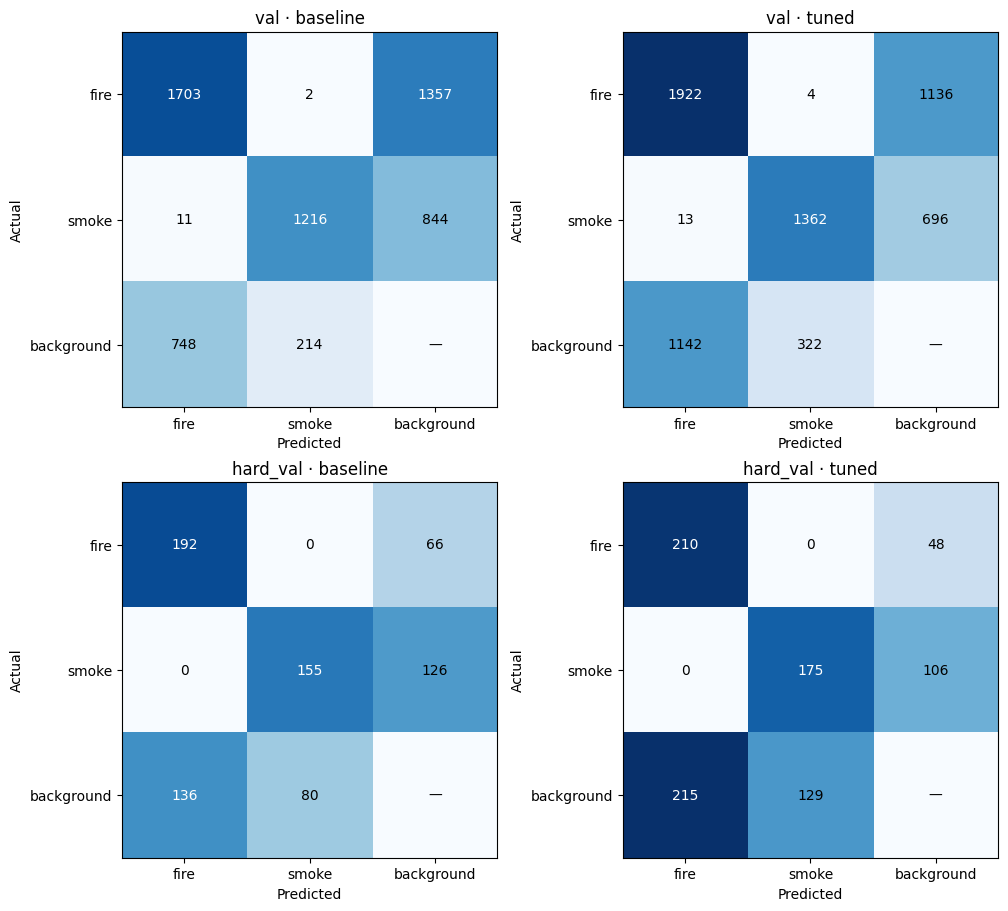

Candidate keys to merge into config.yaml:
detector:
  conf: 0.15
verifier:
  min_prob: 0.35

Reports: /kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier/threshold_tuning


In [30]:
tune_hard = tune_collect("hard_val")
rows, matrices = [], {}

for split, cache in (("val", tune_val), ("hard_val", tune_hard)):
    for name, cutoff in (("baseline", BASE_CUTOFF), ("tuned", TUNED_CUTOFF)):
        scores, cm = tune_score(cache, cutoff)
        rows.append({
            "split": split, "config": name,
            "det_conf": cutoff[0], "ver_conf": cutoff[1], **scores,
        })
        matrices[split, name] = cm

summary = pd.DataFrame(rows)
summary.to_csv(TUNE_OUT / "baseline_vs_tuned.csv", index=False)
display(summary.round(4))

fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
names = ["fire", "smoke", "background"]

for ax, ((split, name), cm) in zip(axes.flat, matrices.items()):
    vmax = max(matrices[split, k].max() for k in ("baseline", "tuned"))
    ax.imshow(cm, cmap="Blues", vmax=vmax)

    for i, j in np.ndindex(cm.shape):
        ax.text(
            j, i, "—" if (i, j) == (2, 2) else str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > .6 * vmax else "black",
        )

    ax.set(
        xticks=range(3), yticks=range(3), xticklabels=names, yticklabels=names,
        xlabel="Predicted", ylabel="Actual", title=f"{split} · {name}",
    )

fig.savefig(TUNE_OUT / "confusion_matrices.png", dpi=150)
plt.show()

patch = {
    "detector": {"conf": TUNED_CUTOFF[0]},
    "verifier": {"min_prob": TUNED_CUTOFF[1]},
}
patch_text = yaml.safe_dump(patch, sort_keys=False)
(TUNE_OUT / "candidate_thresholds.yaml").write_text(patch_text)

print("Candidate keys to merge into config.yaml:")
print(patch_text)
print("Reports:", TUNE_OUT)